# Cue選定再解析 v3
既存700候補・AI品質評価・実測距離を固定して再選定する。v1/v2の z.style は pandas Styler へのアクセスだったため制約が無効だった。z['style'] に修正し各帯×各タイプ最大1文の制約を実行後にも検証する。元データと元結果は不変。新規API呼び出し・モデル読み込み・Qwen・Google Driveは不要。CPU Colab。Secrets: GITHUB_RESULTS_TOKEN。


In [1]:
!pip -q install scipy
import io, json, re, time, base64, hashlib, itertools, unicodedata
from difflib import SequenceMatcher
import numpy as np, pandas as pd, requests, matplotlib.pyplot as plt
from scipy.optimize import milp, Bounds, LinearConstraint
from google.colab import userdata
from IPython.display import display
REPO='ryouy/GraduationThesis'
RESULT_BRANCH='experiments/cue-selection-luna-v1'
RUN_ID='20261126_cue_selection_corrected_v3'
ROOT='experiments/2026-11/1126_cue_selection_luna/results/'+RUN_ID
SOURCE_REF='328e2c15a0ec64bbbd68112edf95ec7dd31485e3'
SOURCE='experiments/2026-11/1124_probe_50pairs/results/20261124_probe50_balanced_v5/pair_probe_scores.csv'
SOURCE_BLOB='c0eebc8cbc5b292cab1cc4f7587fb617f16c60b7'
PAIR_IDS=['C01','C27','C35','C23','C37']
API_MODEL='gpt-6-luna'
EMBED='sentence-transformers/all-mpnet-base-v2'
REV='e8c3b32edf5434bc2275fc9bab85f82640a19130'
STYLES={'structure':'physical structure or characteristic properties','action':'typical action or process','situation':'context or circumstances','function':'purpose, role or effect'}
LEVELS={'very_near':'direct distinctive association','near':'strong common association','medium_near':'association through everyday context','medium_far':'indirect but explainable association','far':'weak but meaningful association','unrelated':'no meaningful association with either concept'}
SETTINGS={'A':(.08,.01),'B':(.06,.02),'C':(.04,.03),'D':(.02,.04)}
Y_WIDTHS=[.05,.075,.10]
MAX_CALLS=400
MAX_ATTEMPTS=4
gh=requests.Session()
gh.headers.update({'Authorization':'Bearer '+userdata.get('GITHUB_RESULTS_TOKEN'),'Accept':'application/vnd.github+json'})
BASE=f'https://api.github.com/repos/{REPO}/contents/'
def dump(o):return (json.dumps(o,ensure_ascii=False,sort_keys=True,indent=2,allow_nan=False)+'\n').encode()
def sha(b):return hashlib.sha256(b).hexdigest()
def blob(b):return hashlib.sha1(b'blob '+str(len(b)).encode()+b'\0'+b).hexdigest()
def get(path,ref=RESULT_BRANCH):
    r=gh.get(BASE+path,params={'ref':ref},timeout=90)
    if r.status_code==404:return None
    r.raise_for_status(); m=r.json()
    if m.get('encoding')=='base64':b=base64.b64decode(m['content'])
    else:
        r=gh.get(BASE+path,params={'ref':ref},headers={'Accept':'application/vnd.github.raw+json'},timeout=90);r.raise_for_status();b=r.content
    assert blob(b)==m['sha']
    return b
def put(name,b):
    path=ROOT+'/'+name
    old=get(path)
    if old is not None:
        if old!=b:raise RuntimeError('Immutable conflict: '+path)
        return
    for i in range(8):
        try:
            r=gh.put(BASE+path,json={'branch':RESULT_BRANCH,'message':'Cue selection: '+name,'content':base64.b64encode(b).decode()},timeout=90)
        except requests.RequestException:
            old=get(path)
            if old is not None:
                if old!=b:raise RuntimeError('Immutable conflict: '+path)
                return
            time.sleep(min(60,2**i))
            continue
        if r.ok:return
        if r.status_code not in (409,422,429,500,502,503,504):r.raise_for_status()
        old=get(path)
        if old is not None:
            if old!=b:raise RuntimeError('Immutable conflict: '+path)
            return
        time.sleep(min(60,2**i))
    raise RuntimeError('GitHub save retries exhausted: '+path)
def save_df(name,d):put(name,d.to_csv(index=False).encode())

INPUT_ROOT='experiments/2026-11/1126_cue_selection_luna/results/20261126_cue_selection_luna_v1'
INPUT_REF=RESULT_BRANCH
raw=get(INPUT_ROOT+'/cue_candidates_measured.csv',INPUT_REF)
assert sha(raw)=='be48364c113d57171e87b4b61bced56b262ec178d2edfe4afb9c888558c2eb1f'
df=pd.read_csv(io.BytesIO(raw))
assert len(df)==700 and df.quality_pass.sum()==622 and df.id.is_unique
assert set(df['style'])==set(STYLES)
assert set(df['pair'])==set(PAIR_IDS)
assert np.isfinite(df[['d_x','d_y']]).all().all()
df[['d_x','d_y']]=df[['d_x','d_y']].astype('float32')
bounds_raw=get(INPUT_ROOT+'/distance_bounds.csv',INPUT_REF)
assert sha(bounds_raw)=='ce0b57df782ef6b64c8bbd4ddbc529bf9dacd817460fff1087f98d7a6b6cd0b4'
old_bounds=pd.read_csv(io.BytesIO(bounds_raw))
def norm(s):return ' '.join(unicodedata.normalize('NFKC',s).casefold().split())
config={'input_ref':INPUT_REF,'input_path':INPUT_ROOT,'input_sha256':sha(raw),'settings':SETTINGS,'y_half_widths':Y_WIDTHS,'algorithm':'v2 corrected style column plus post-selection constraints','status':'exploratory'}
put('config.json',dump(config))
print('Loaded',len(df),'candidates; quality pass',df.quality_pass.sum())


Loaded 700 candidates; quality pass 622


In [2]:
def select(g,centers,tol,gap,control):
    mid=(centers[:-1]+centers[1:])/2
    lo=np.maximum(centers-tol,np.r_[0,mid+gap/2])
    hi=np.minimum(centers+tol,np.r_[mid-gap/2,2])
    a=g.copy();a['band']=-1
    for b in range(5):
        a.loc[(a.related==1)&a.d_x.between(lo[b],hi[b]),'band']=b
    a.loc[a.related.eq(0),'band']=5
    a=a[a.band>=0].sort_values('id')
    yc=float(g[g.related==1].d_y.median())
    slots=list(itertools.product(range(6),STYLES))
    best=None
    for w in (Y_WIDTHS if control else [None]):
        z=a if w is None else a[(a.band==5)|(abs(a.d_y-yc)<=w)]
        if z.empty:continue
        A=np.array([((z.band==b)&(z['style']==s)).astype(float) for b,s in slots])
        # pairwise near-duplicate exclusions within selected set
        extra=[]
        cues=z.cue.tolist()
        for i,j in itertools.combinations(range(len(z)),2):
            if SequenceMatcher(None,norm(cues[i]),norm(cues[j])).ratio()>=.80:
                v=np.zeros(len(z));v[i]=v[j]=1;extra.append(v)
        if extra:A=np.vstack([A,extra])
        cost=np.array([abs(r.d_x-centers[r.band]) if r.band<5 else 0 for r in z.itertuples()])
        if control:cost+=np.where(z.band<5,abs(z.d_y-yc),0)
        # deterministic tie break; big reward ensures maximum count
        cost=cost-100+np.arange(len(z))*1e-8
        res=milp(cost,integrality=np.ones(len(z)),bounds=Bounds(0,1),constraints=LinearConstraint(A,0,1),options={'time_limit':30})
        if not res.success:raise RuntimeError('MILP did not prove optimum: '+str(res.message))
        sel=z.iloc[np.flatnonzero(res.x>.5)].copy()
        assert len(sel)<=24 and sel.id.is_unique
        assert not sel.duplicated(['band','style']).any()
        assert sel.quality_pass.all()
        assert len(sel[sel.band<5])<=20 and len(sel[sel.band==5])<=4
        assert np.all(A @ (res.x>.5).astype(int)<=1+1e-9)
        for rr in sel[sel.band<5].itertuples():
            assert lo[rr.band]-1e-7<=rr.d_x<=hi[rr.band]+1e-7
            if w is not None:assert abs(rr.d_y-yc)<=w+1e-7
        if best is None or len(sel)>len(best[0]):best=(sel,w)
        if len(sel)==24:break
    if best is None:best=(a.iloc[:0],None)
    return best[0],best[1],lo,hi,yc
all_sel=[];stats=[];bounds=[]
for pid,whole in df.groupby('pair'):
    g=whole[whole.quality_pass].copy();rel=g[g.related==1]
    if len(rel)<40:
        for k in SETTINGS:
            for control in [False,True]:stats.append({'pair':pid,'setting':k,'y_control':control,'n':0,'complete':False,'status':'insufficient_initial_quality'})
        continue
    centers=np.array([np.median(v) for v in np.array_split(np.sort(rel.d_x.to_numpy()),5)])
    for k,(tol,gap) in SETTINGS.items():
        for control in [False,True]:
            sel,w,lo,hi,yc=select(g,centers,tol,gap,control)
            r=sel[sel.band<5];rho=r.d_x.corr(r.d_y,method='spearman') if len(r)>2 else np.nan
            means=r.groupby('band').d_y.mean()
            spread=means.max()-means.min() if len(means)==5 else np.nan
            stat={'pair':pid,'setting':k,'y_control':control,'n':len(sel),'n_related':len(r),'complete':len(sel)==24,'y_half_width':w,'rho':rho,'y_mean_spread':spread,'y_sd':r.d_y.std(),'y_target_met':bool(len(r)==20 and abs(rho)<=.30 and spread<=.05),'status':'provisional' if len(sel)==24 else 'shortage'}
            stat['missing_slots']=';'.join(f'{b}:{st}' for b,st in itertools.product(range(6),STYLES) if not ((sel.band==b)&(sel['style']==st)).any())
            stats.append(stat)
            for b in range(5):bounds.append({'pair':pid,'setting':k,'y_control':control,'band':b,'center':centers[b],'lo':lo[b],'hi':hi[b]})
            all_sel.append(sel.assign(setting=k,y_control=control))
s=pd.DataFrame(stats);b=pd.DataFrame(bounds);selected=pd.concat(all_sel,ignore_index=True) if all_sel else pd.DataFrame(columns=list(df.columns)+['band','setting','y_control'])
assert s.n.between(0,24).all()
assert len(s)==40
assert not selected.duplicated(['pair','setting','y_control','band','style']).any()
assert np.allclose(b[['center','lo','hi']].to_numpy(),old_bounds[['center','lo','hi']].to_numpy(),atol=1e-6)
save_df('selection_summary.csv',s);save_df('distance_bounds.csv',b);save_df('cue_selected_PROVISIONAL.csv',selected)
display(s)
display(s.groupby(['setting','y_control']).agg(complete_pairs=('complete','sum'),slots=('n','sum')))



,pair,setting,y_control,n,n_related,complete,y_half_width,rho,y_mean_spread,y_sd,y_target_met,status,missing_slots
0,C01,A,False,23,19,False,NaN,0.249123,0.103965,0.069484,False,shortage,0:situation
1,C01,A,True,23,19,False,0.100,0.315789,0.039403,0.029906,False,shortage,0:situation
2,C01,B,False,22,18,False,NaN,0.248710,0.114060,0.071450,False,shortage,0:situation;3:structure
3,C01,B,True,22,18,False,0.100,0.356037,0.046348,0.031730,False,shortage,0:situation;3:structure
4,C01,C,False,21,17,False,NaN,0.262255,0.114060,0.073557,False,shortage,0:situation;2:function;3:structure
5,C01,C,True,21,17,False,0.100,0.367647,0.060032,0.034198,False,shortage,0:situation;2:function;3:structure
6,C01,D,False,20,16,False,NaN,0.311765,0.128669,0.073092,False,shortage,0:situation;2:structure;2:function;3:structure
7,C01,D,True,20,16,False,0.075,0.273529,0.047567,0.033199,False,shortage,0:situation;2:structure;2:function;3:structure
8,C23,A,False,23,19,False,NaN,0.652632,0.198229,0.095827,False,shortage,1:function
9,C23,A,True,23,19,False,0.100,0.542105,0.080000,0.041886,False,shortage,1:function


complete_pairs  slots
setting y_control                       
A       False                   3    118
        True                    0    105
B       False                   1    115
        True                    0    102
C       False                   1    110
        True                    0     93
D       False                   0    102
        True                    0     84

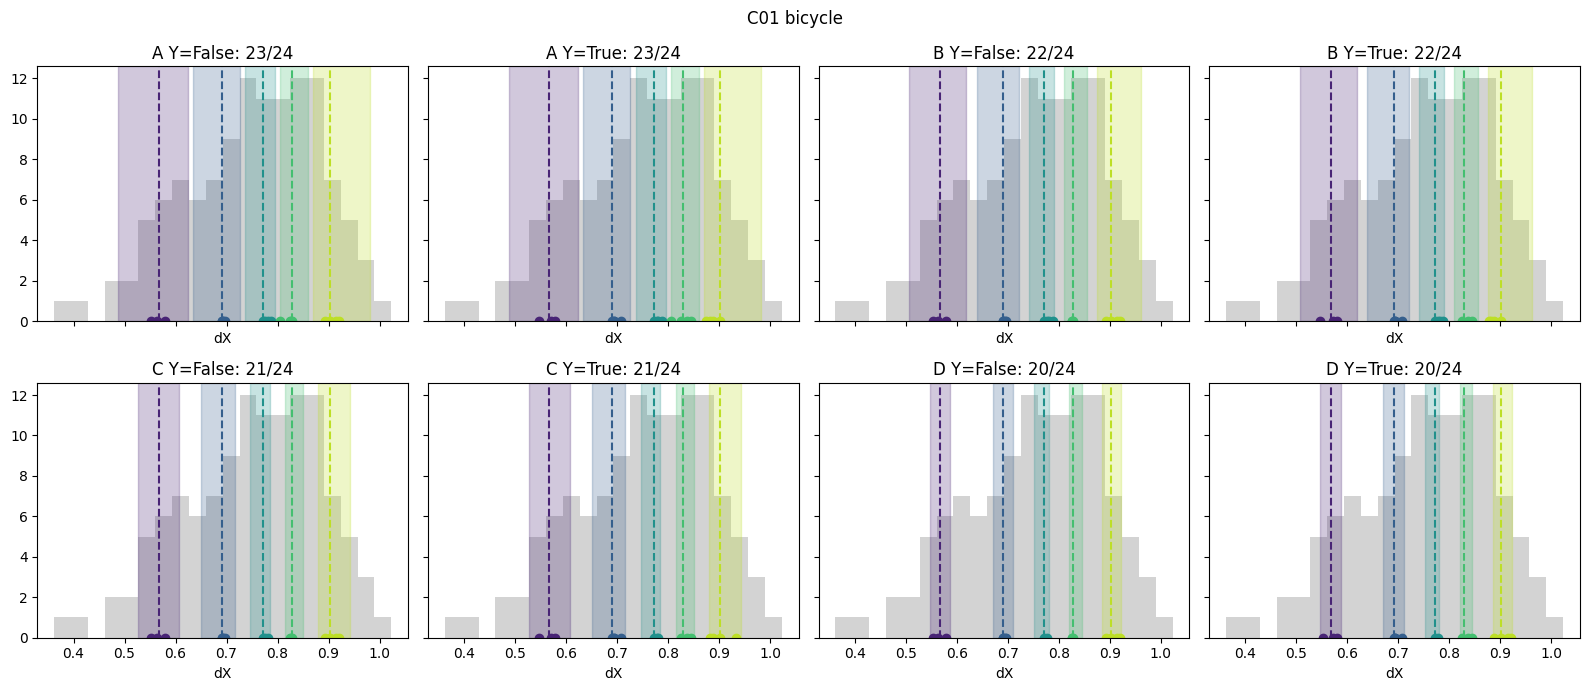

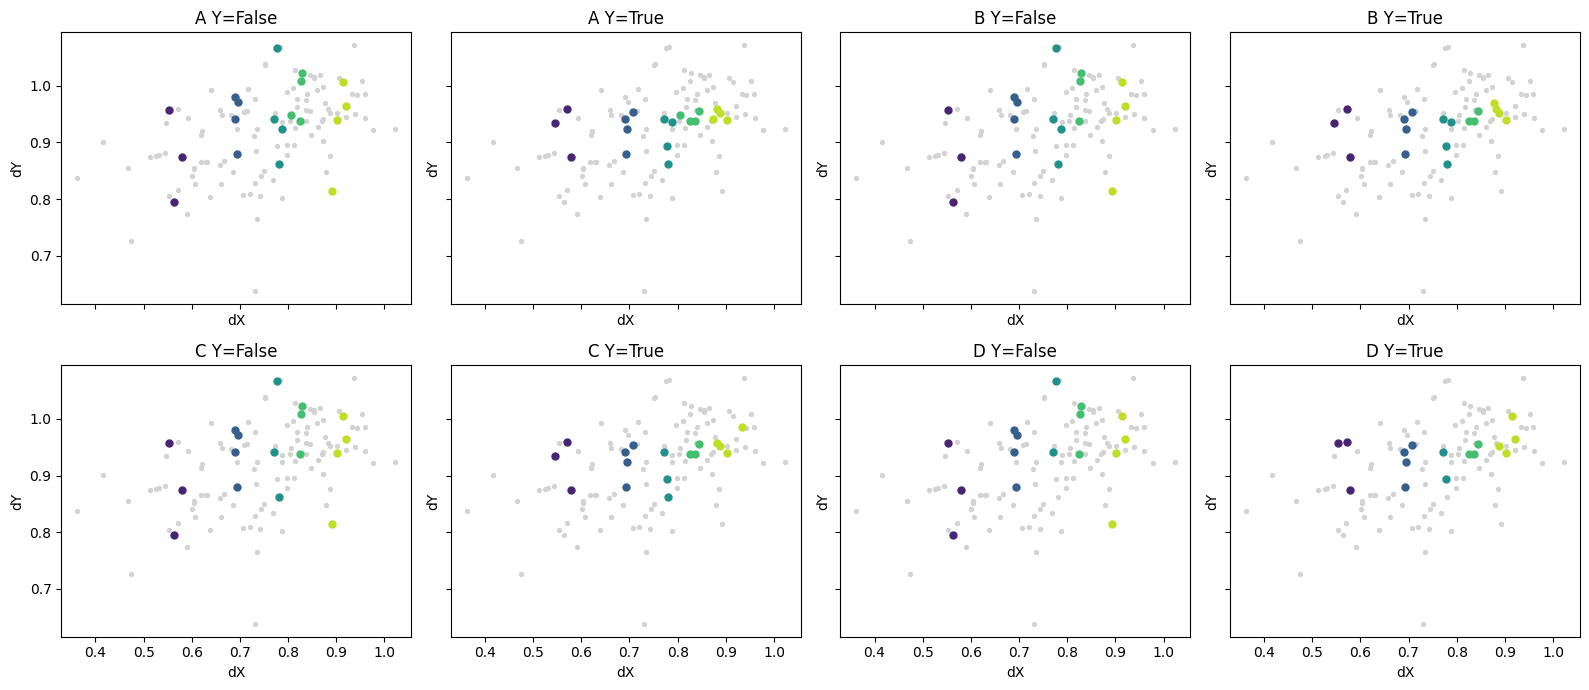

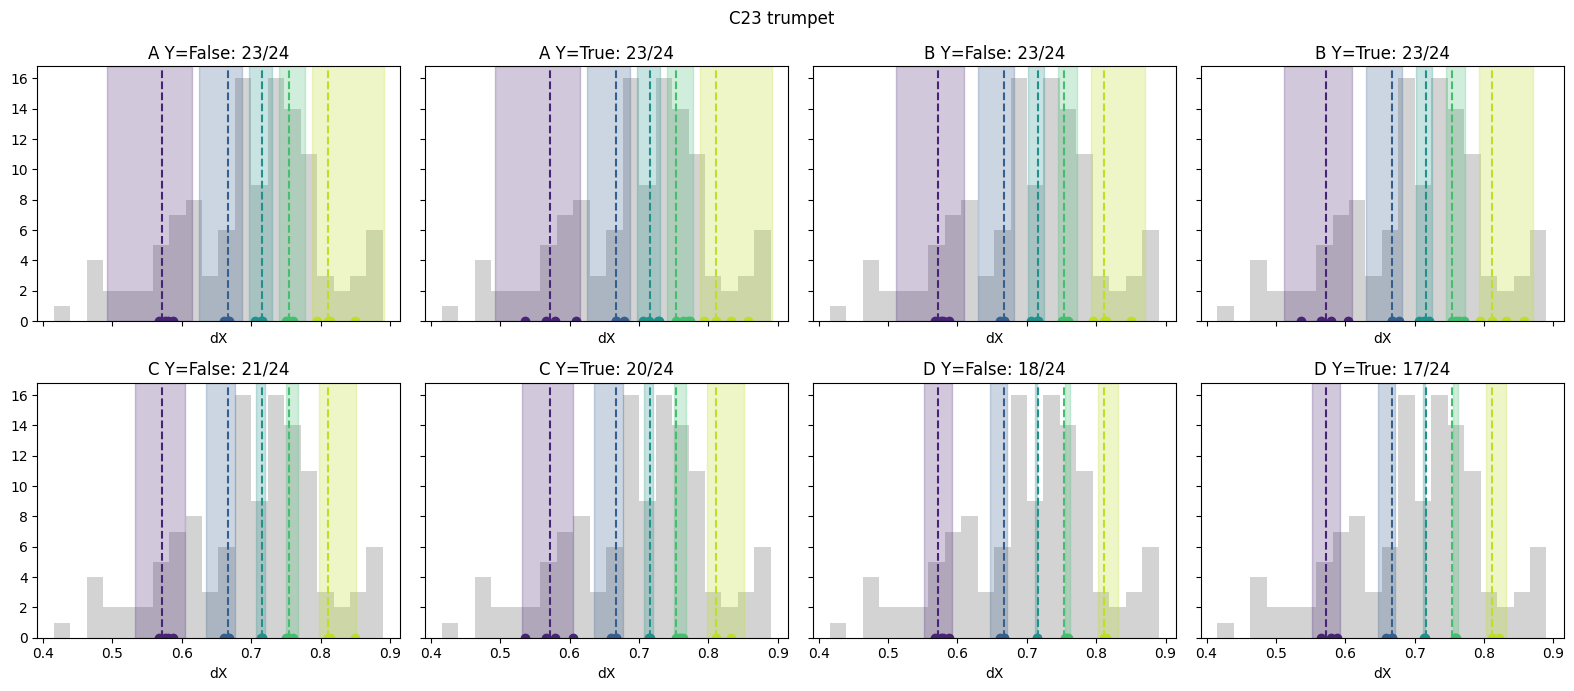

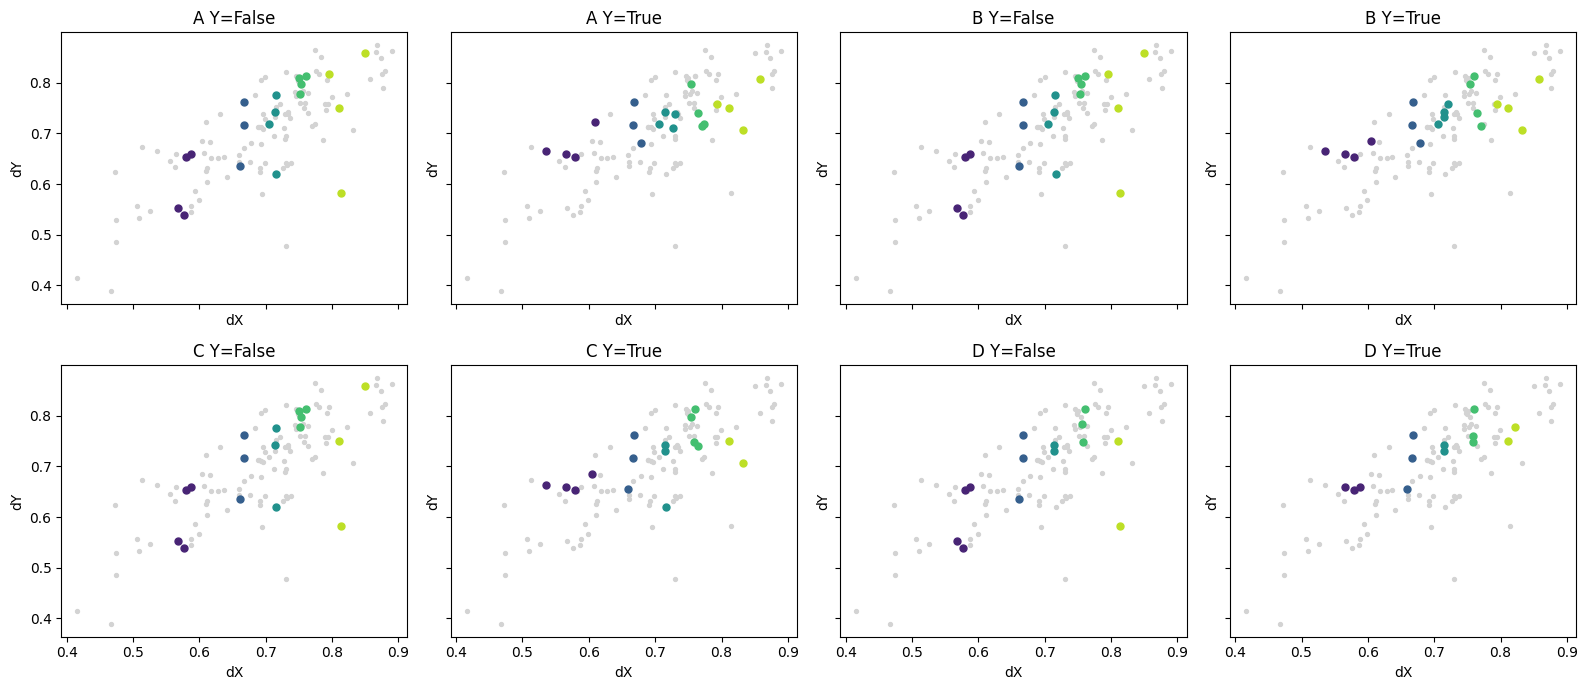

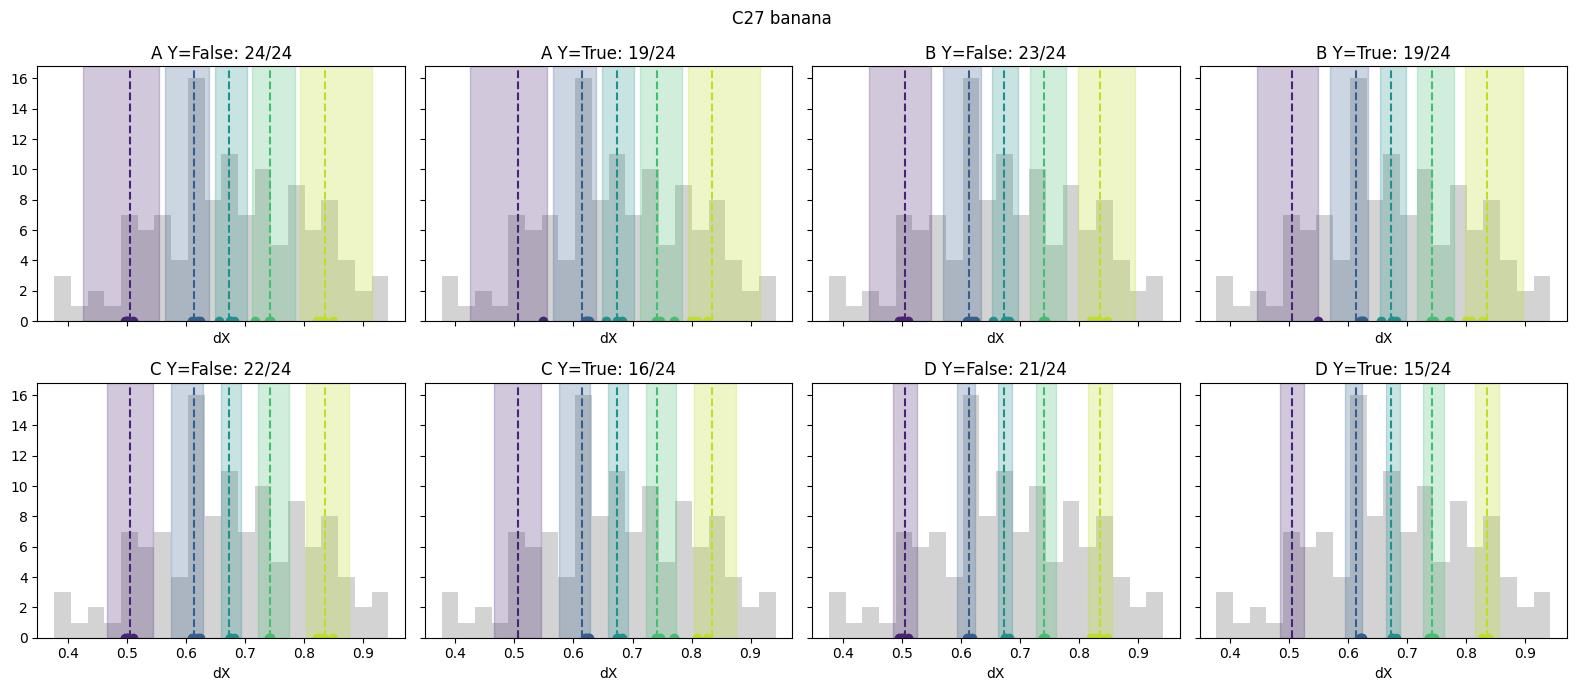

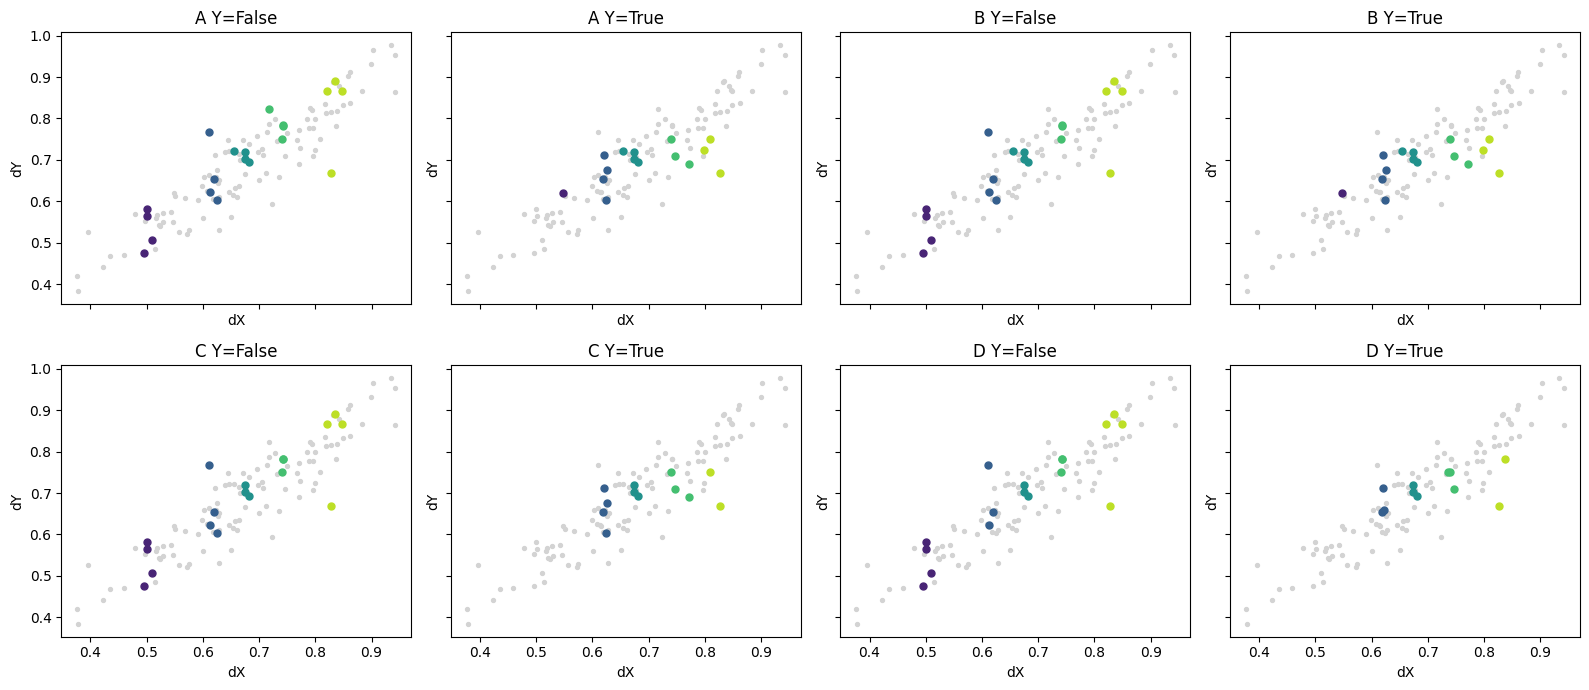

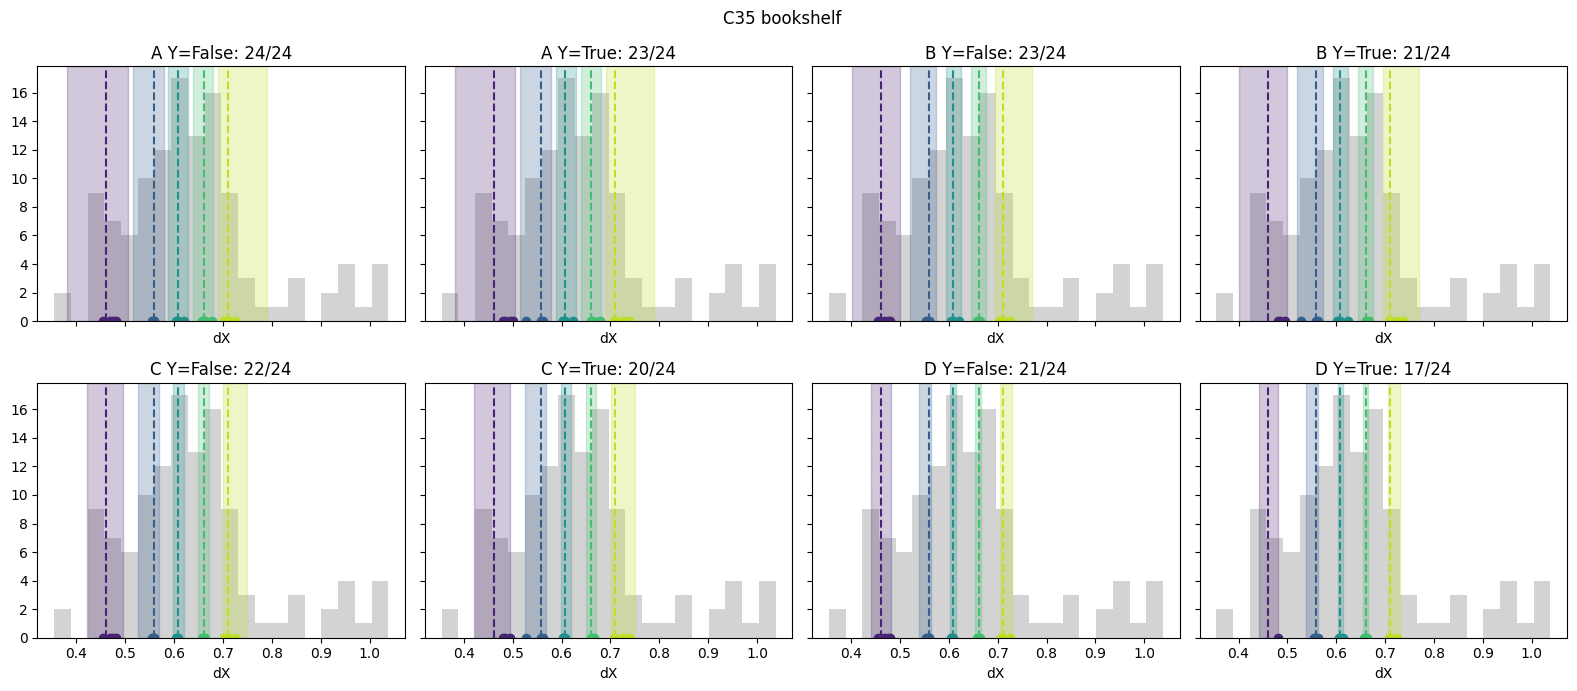

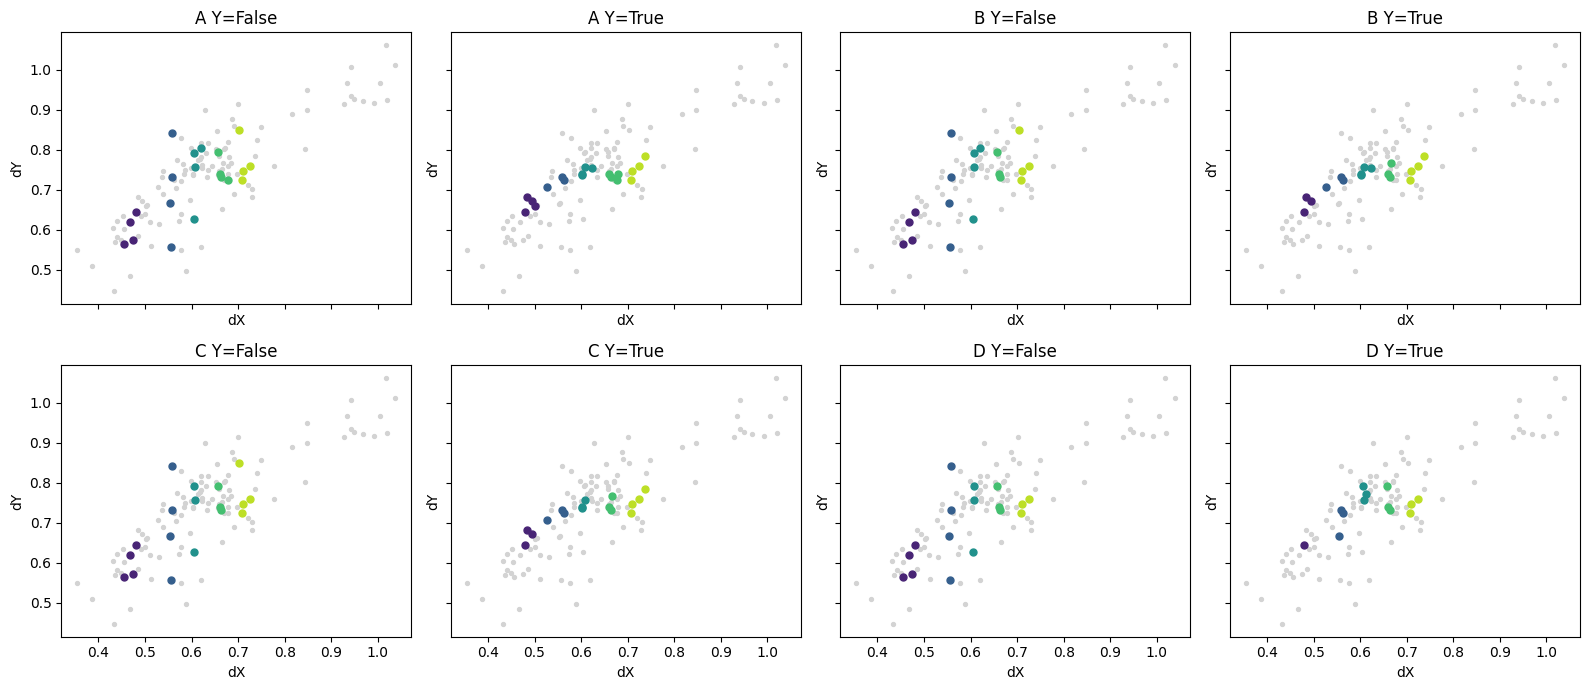

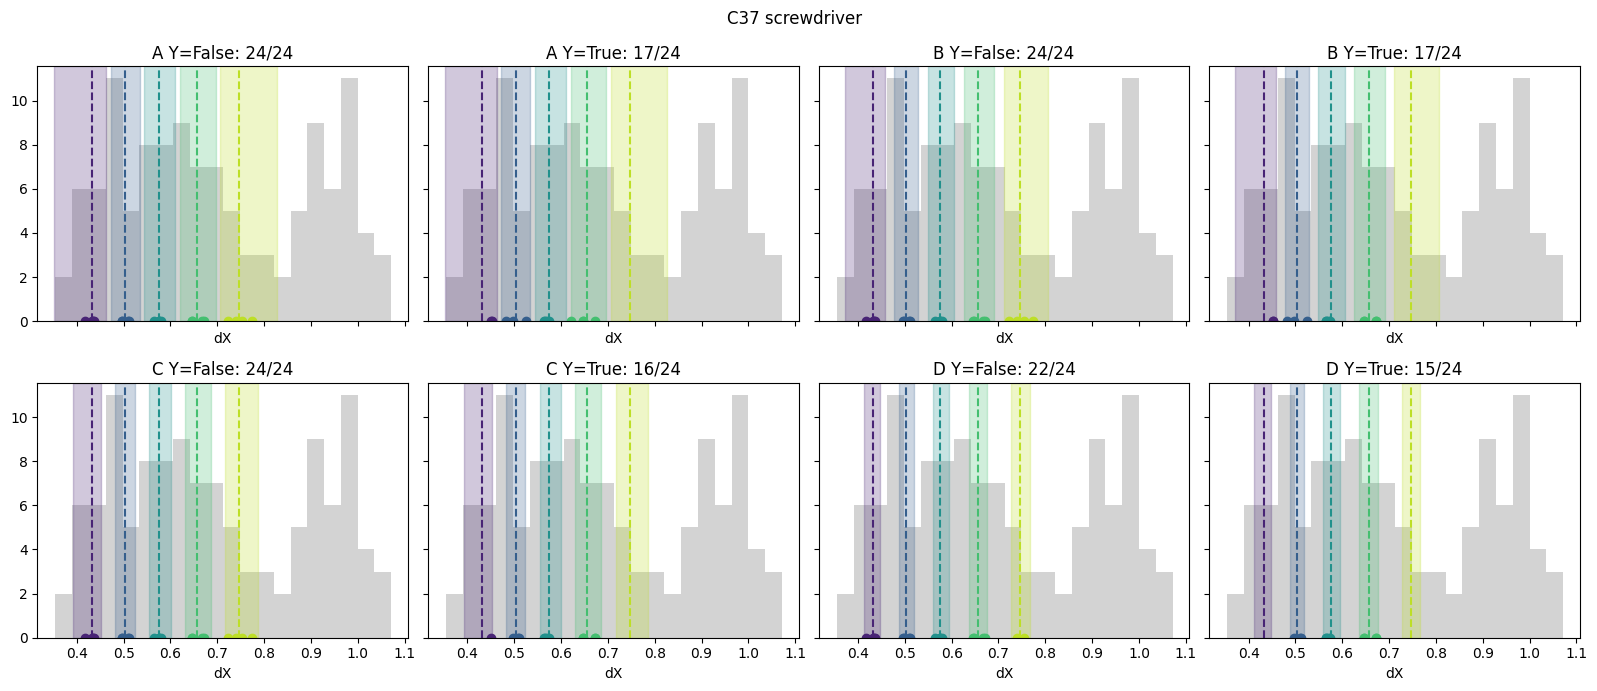

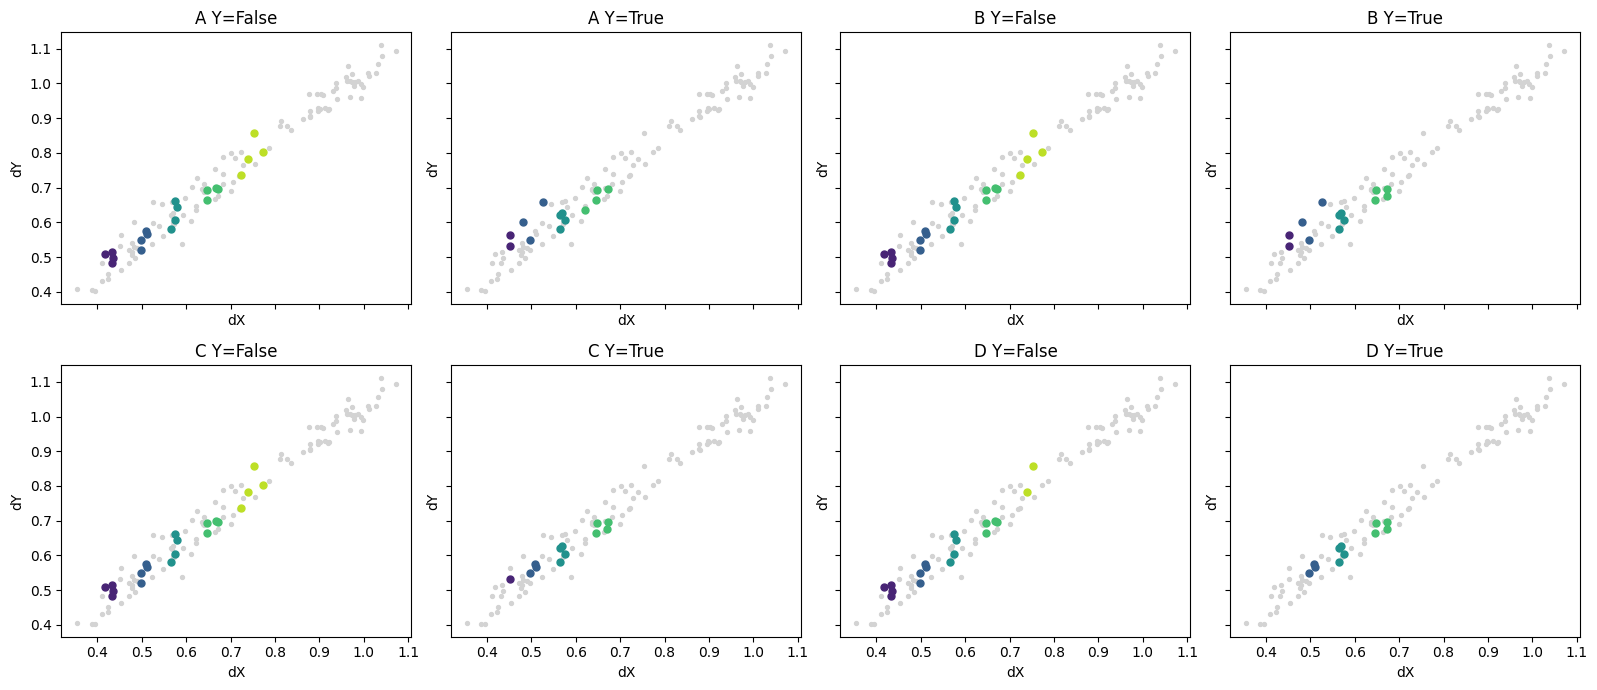

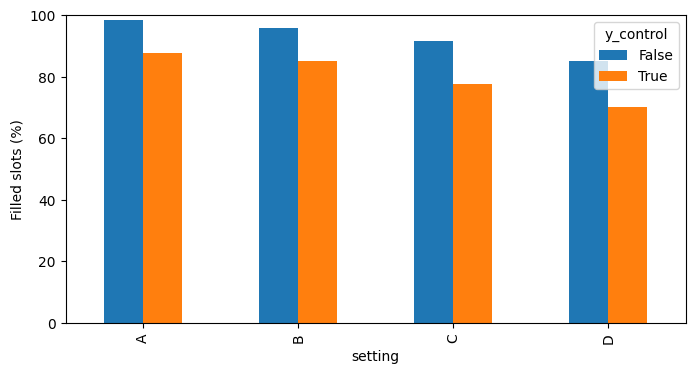

Results: https://github.com/ryouy/GraduationThesis/tree/experiments/cue-selection-luna-v1/experiments/2026-11/1126_cue_selection_luna/results/20261126_cue_selection_corrected_v3


In [3]:
def figsave(name,fig):
    buf=io.BytesIO();fig.savefig(buf,format='png',dpi=150,bbox_inches='tight');put('figures/'+name+'.png',buf.getvalue());plt.show();plt.close(fig)
colors=plt.cm.viridis(np.linspace(.1,.9,5))
for pid,g in df.groupby('pair'):
    fig,axs=plt.subplots(2,4,figsize=(16,7),sharex=True,sharey=True)
    for ax,(k,control) in zip(axs.flat,itertools.product(SETTINGS,[False,True])):
        z=selected[(selected.pair==pid)&(selected.setting==k)&(selected.y_control==control)]
        bb=b[(b.pair==pid)&(b.setting==k)&(b.y_control==control)] if len(b) else b
        ax.hist(g[g.related==1].d_x,bins=20,color='lightgray')
        for rr in bb.itertuples():
            if rr.hi>=rr.lo:ax.axvspan(rr.lo,rr.hi,color=colors[rr.band],alpha=.25)
            ax.axvline(rr.center,color=colors[rr.band],ls='--')
        for rr in z[z.band<5].itertuples():ax.plot(rr.d_x,0,'o',color=colors[rr.band])
        ax.set_title(f'{k} Y={control}: {len(z)}/24');ax.set_xlabel('dX')
    fig.suptitle(pid+' '+g.x.iloc[0]);fig.tight_layout();figsave(pid+'_distance',fig)
    fig,axs=plt.subplots(2,4,figsize=(16,7),sharex=True,sharey=True)
    for ax,(k,control) in zip(axs.flat,itertools.product(SETTINGS,[False,True])):
        z=selected[(selected.pair==pid)&(selected.setting==k)&(selected.y_control==control)&(selected.band<5)]
        ax.scatter(g[g.related==1].d_x,g[g.related==1].d_y,s=8,c='lightgray')
        for band,t in z.groupby('band'):ax.scatter(t.d_x,t.d_y,color=colors[int(band)],s=25)
        ax.set_title(f'{k} Y={control}');ax.set_xlabel('dX');ax.set_ylabel('dY')
    fig.tight_layout();figsave(pid+'_xy',fig)
fig,ax=plt.subplots(figsize=(8,4))
v=s.groupby(['setting','y_control']).n.sum().unstack().reindex(SETTINGS)
v.div(120).mul(100).plot.bar(ax=ax);ax.set_ylabel('Filled slots (%)');ax.set_ylim(0,100);figsave('slot_fill',fig)
# Human-review sample: each setting/pair, reproducible 10%, plus all uncertain audit items.
sample=selected.groupby(['pair','setting','y_control'],group_keys=False).sample(frac=.1,random_state=42) if len(selected) else selected
review=pd.concat([sample,df[df[['fact','style_audit','exposure']].eq('uncertain').any(axis=1)]],ignore_index=True).drop_duplicates('id')
review['human_decision']='';review['human_notes']='';save_df('human_review_pending.csv',review)
put('manifest.json',dump({'status':'provisional_human_and_probe_overlap_audit_pending','config_sha256':sha(dump(config)),'input_ref':INPUT_REF,'input_sha256':sha(raw),'n_candidates':len(df),'n_quality_pass':int(df.quality_pass.sum()),'n_selected_across_settings':len(selected),'files':{n:sha(get(ROOT+'/'+n)) for n in ['selection_summary.csv','distance_bounds.csv','cue_selected_PROVISIONAL.csv','human_review_pending.csv']}}))
print('Results: https://github.com/'+REPO+'/tree/'+RESULT_BRANCH+'/'+ROOT)



旧v1の採択結果は無効。v3も刺激凍結ではない。Y相関・帯間平均差は診断値のみ。部分採択から完全セットの性能は推定しない。
